In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.multivariate.factor import Factor
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from sklearn.cluster import KMeans


In [48]:
df = pd.read_excel("DATA.xlsx", sheet_name = 2)
df.columns = ["regions", "x1", "x2", "x3", "x4", "x5"]
new_df = df.set_index("regions")

In [49]:
ylabels = ["тыс. т.", " млн. куб. м.", "млн. куб. м", "руб.", "руб."]
i = 0

for column in new_df.columns:
    plt.figure(figsize = (12, 4))
    new_df.boxplot(column = [column])
    plt.ylabel(ylabels[i])
    plt.savefig(f"boxplots/{i}s.png")
    plt.close()
    i += 1

In [50]:
corr = new_df.corr().round(3)
corr.style.background_gradient()

,x1,x2,x3,x4,x5
x1,1.000000,0.353000,0.385000,0.170000,0.189000
x2,0.353000,1.000000,0.545000,0.040000,0.048000
x3,0.385000,0.545000,1.000000,0.073000,0.134000
x4,0.170000,0.040000,0.073000,1.000000,0.689000
x5,0.189000,0.048000,0.134000,0.689000,1.000000


In [51]:
qrs = []
maxes = []
mines = []
desc_stat = new_df.describe()
desc_stat = desc_stat.T

for column in new_df.columns:
    qrs.append(count_iqr(new_df[column].values))
    maxes.append(new_df[new_df[column] == new_df[column].max()].index[0])
    mines.append(new_df[new_df[column] == new_df[column].min()].index[0])

desc_stat["iqr"] = qrs
desc_stat["spread"] = desc_stat["max"] - desc_stat["min"]
desc_stat["min_region"] = mines
desc_stat["max_region"] = maxes

desc_stat.round(1)

,count,mean,std,min,25%,50%,75%,max,iqr,spread,min_region,max_region
x1,78.0,188.3,358.6,2.0,33.5,105.5,197.2,2632.0,163.8,2630.0,Республика Ингушетия,Красноярский край
x2,78.0,541.8,720.4,7.0,111.2,212.5,592.8,3539.0,481.5,3532.0,Республика Алтай,Ленинградская область
x3,78.0,121.3,150.8,0.0,31.2,73.5,133.2,806.0,102.0,806.0,Чеченская Республика,Московская область
x4,78.0,150463.1,127285.3,44488.0,83458.2,112334.0,148955.0,663508.0,65496.8,619020.0,Республика Ингушетия,Магаданская область
x5,78.0,706951.8,469905.0,159603.5,450569.1,592863.7,800448.7,3303417.0,349879.6,3143813.5,Республика Ингушетия,Сахалинская область


In [52]:
desc_stat.to_excel("descript_stat.xlsx")

In [53]:
corr.to_excel("correlation.xlsx")

In [54]:
std_df = new_df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

In [55]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(92.63404079079315, 1.6063039445413959e-15)

In [56]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.5855622018462341

In [57]:
fa = Factor(std_df, n_factor = 5, method = "pa")
res = fa.fit()

In [58]:
res.rotate(method = "varimax")
res.get_loadings_frame(threshold=0)

,factor 0,factor 1,factor 2,factor 3
x5,0.840473,0.075094,-0.114048,0.000901
x4,0.833303,0.025628,0.113644,0.025591
x3,0.077162,0.764741,-0.103874,0.021389
x2,0.008692,0.729127,0.126361,0.000420
x1,0.182656,0.481061,0.007454,0.170417


In [59]:
sum(sorted(res.eigenvals)[3:])/sum(res.eigenvals)*100

97.41652455448087

In [73]:
res.eigenvals

array([ 1.64566830e+00,  1.15723980e+00,  5.26488794e-02,  2.16840488e-02,
       -1.15900709e-07])

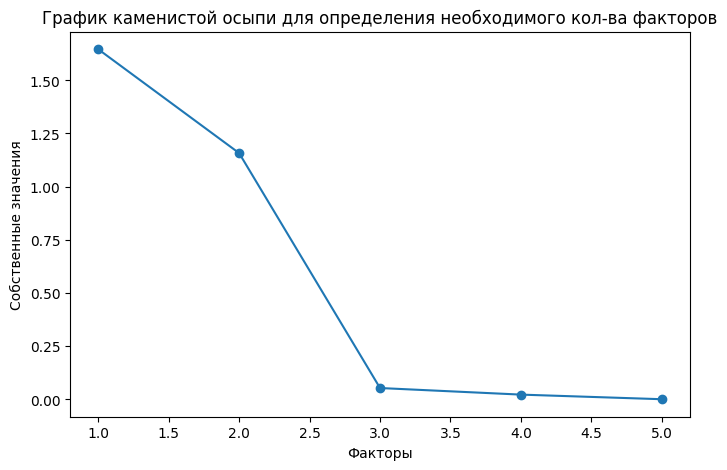

In [60]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(1,std_df.shape[1]+1), res.eigenvals)
plt.plot(range(1,std_df.shape[1]+1), res.eigenvals)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones_scree.png")

In [61]:
load = res.loadings.T[:2].T
pces = np.dot(std_df, load)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

data = {"regions": std_df.index, "f1": pc1, "f2": pc2}

integral_char = pd.DataFrame(data)
integral_char = integral_char.set_index("regions")

In [62]:
sk_ac = AgglomerativeClustering(n_clusters=3, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(integral_char)

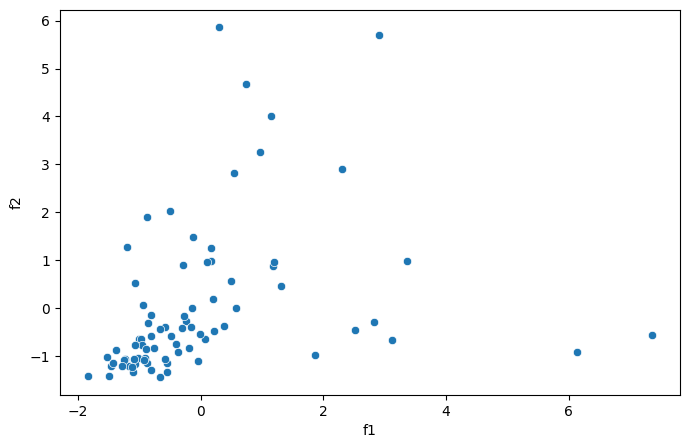

In [63]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2")

plt.savefig("ward_scatter.png")

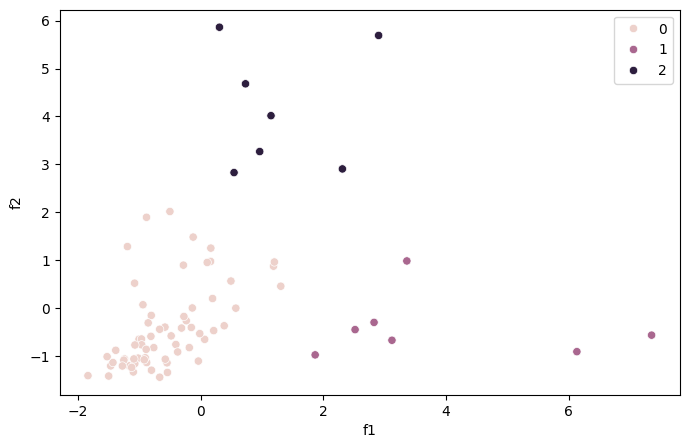

In [64]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = sk_ac_pred_res)

plt.savefig("ward_scatter_clusters.png")

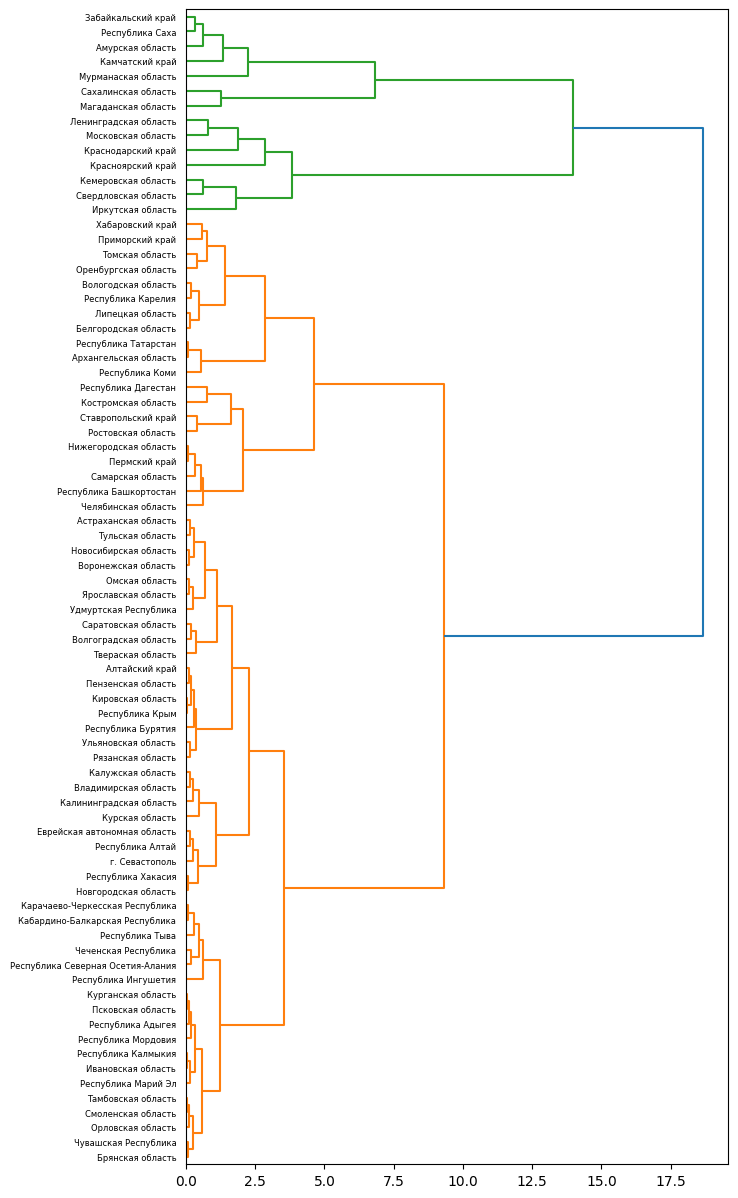

In [65]:
Z = linkage(integral_char, method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(7, 15))
dendrogram(Z, color_threshold=15, orientation="right", labels = integral_char.index)
plt.savefig("ward_dendro.png")

In [66]:
integral_char["class"] = sk_ac_pred_res
integral_char.to_excel("ward_clusters.xlsx")

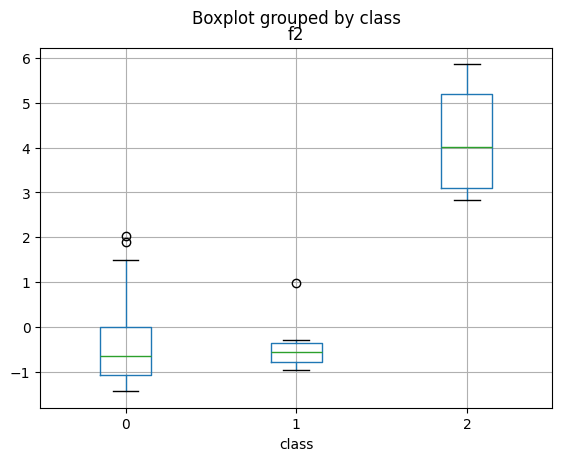

In [67]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/ward_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/ward_pc2_clust_boxs.png")

In [68]:
kmeans = KMeans(n_clusters=3)
k_means_predict = kmeans.fit_predict(integral_char)

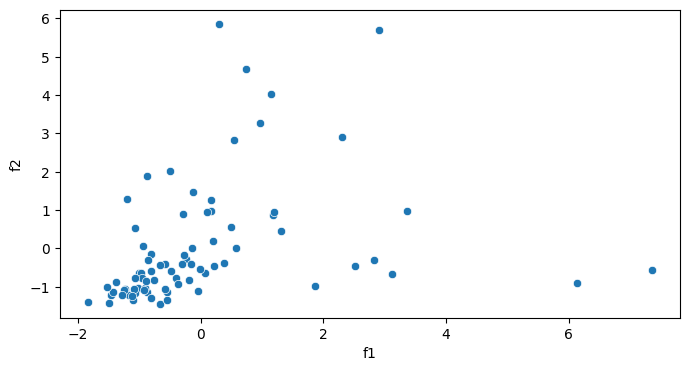

In [69]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2")
plt.savefig("kmeans_scatter.png")

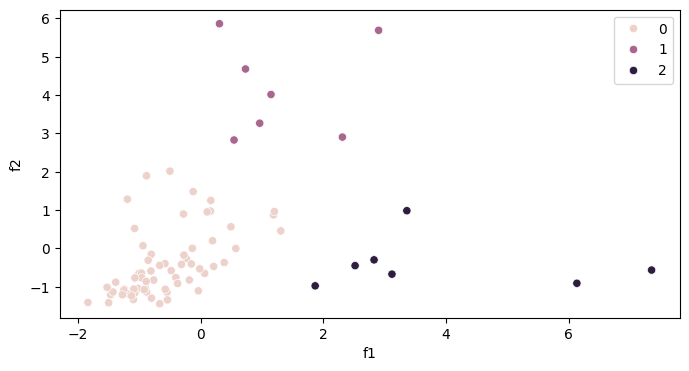

In [70]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = k_means_predict)
plt.savefig("kmeans_scatter_clusters.png")

In [71]:
integral_char["class"] = k_means_predict
integral_char.to_excel("kmeans_clusters.xlsx")


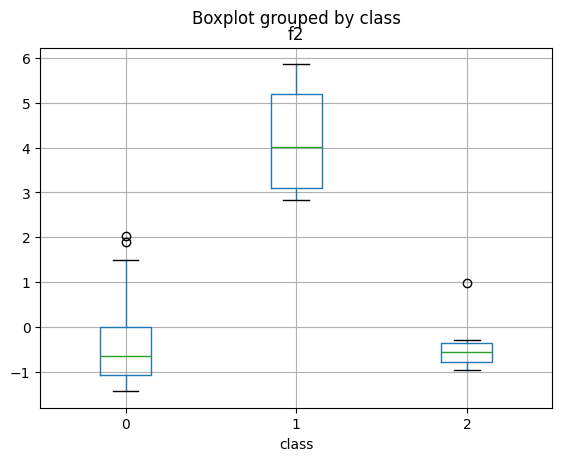

In [72]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/kmeans_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/kmeans_pc2_clust_boxs.png")